# Step 2 — 하이퍼파라미터 최적화 (Hyperparameter Optimisation via Optuna)

- **목적 (Objective)**: Step 1 채택 구성(`lgbm_fe`, 23 feature)의 하이퍼파라미터를 탐색하여 OOF AUC `0.95934` 초과.
- **단일 변경점 (§3-4)**: 피처 구성은 Step 1에서 **고정**. 본 단계의 변경점은 하이퍼파라미터뿐이다.

### 탐색 설계 (Search Design)

| 항목 | 설정 | 근거 |
|---|---|---|
| 목적 함수 | **full 5-Fold pooled OOF AUC** | §3-5 개정 예산(1회 ≈60초)으로 직접 최적화 가능 |
| 고정 파라미터 | `learning_rate=0.05`, `num_boost_round=5000`, `early_stopping(100)` | 탐색 조건 = 확정 조건. **search-refit gap 제거** |
| 샘플러 | Optuna TPE (`seed=42`) | 재현성 |
| 탐색 공간 | `num_leaves`, `min_child_samples`, `feature_fraction`, `bagging_fraction`+`freq`, `lambda_l1/l2` | 복잡도·샘플링·정규화 3축 |

### 낙관 편향 통제 (Optimism Control) — §1-5 A와 동일한 성격

50회 시행의 **최댓값** 자체가 OOF에 대한 선택 편향을 갖는다. 따라서:
1. Optuna가 고른 파라미터를 **seed 3개로 재학습해 평균 OOF**를 산출한다.
2. **Step 1 챔피언도 동일한 seed 3개로 재측정**한다.
   3-seed 평균(분산 감소)과 1-seed 단일값을 비교하면 튜닝 모델에 부당한 이점이 생기기 때문이다.
3. 최종 판정은 **3-seed 평균끼리**, 그리고 **4/5 Fold 규칙**으로 내린다.

---

## 1. 환경 설정 및 Step 1 구성 복원 (Environment & Champion Restoration)

In [1]:
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
START_TIME = time.time()
COLOR_MAIN, COLOR_ALT, COLOR_MUTED = "#2a78d6", "#eb6834", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold",
})
print("optuna", optuna.__version__, "| lightgbm", lgb.__version__)

optuna 5.0.0 | lightgbm 4.7.0


/Users/chanjong/sesac-ai/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
REQUIRED_FILES = ["train.csv", "test.csv", "sample_submission.csv"]
has_all = lambda f: all((f / n).is_file() for n in REQUIRED_FILES)
kaggle = Path("/kaggle/input")
cands = (sorted({p.parent for p in kaggle.glob("**/train.csv") if has_all(p.parent)}) if kaggle.exists()
         else list(dict.fromkeys(p.resolve() for p in (Path("data"), Path("../data")) if has_all(p))))
DATA_DIR = cands[0]
OUT_DIR = Path("/kaggle/working/outputs") if Path("/kaggle/working").exists() else Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
TARGET = "satisfaction"
CAT_COLS = ["Gender", "Customer Type", "Type of Travel", "Class"]
y = train[TARGET].astype(int)

# --- Step 1 채택 구성 복원: BASE 21 feature + 빈도 인코딩 (fold별 fit) ---
X = train.drop(columns=["id", TARGET]).copy()
X_test = test.drop(columns=["id"]).copy()
for col in CAT_COLS:
    cats = sorted(train[col].unique())
    X[col] = pd.Categorical(X[col], categories=cats)
    X_test[col] = pd.Categorical(X_test[col], categories=cats)

FREQ_COLS = ["Age", "Flight Distance"]


def add_freq_features(fit_df, *apply_dfs):
    counts = {c: fit_df[c].value_counts() for c in FREQ_COLS}
    out = []
    for df in (fit_df, *apply_dfs):
        df = df.copy()
        for c in FREQ_COLS:
            df[f"{c}_freq"] = df[c].map(counts[c]).fillna(0).astype(float)
        out.append(df)
    return out


N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(train, y))
fold_id = np.full(len(train), -1)
for k, (_, va_idx) in enumerate(FOLDS):
    fold_id[va_idx] = k

_ref = pd.read_csv(OUT_DIR / "oof_lgbm_fe.csv", usecols=["id", "fold"])
_chk = pd.DataFrame({"id": train["id"].values, "fold": fold_id}).merge(
    _ref, on="id", suffixes=("_new", "_ref"), validate="one_to_one")
assert len(_chk) == len(train) and (_chk["fold_new"] == _chk["fold_ref"]).all(), "Fold 계약 불일치"
print("fold 계약 검증 PASS  |  features:", X.shape[1], "+ 2 (freq, fold별 fit)")

# Step 1 챔피언의 fold 벡터 (대응 비교 대상)
_fe = pd.read_csv(OUT_DIR / "oof_lgbm_fe.csv")
CHAMP_FOLDS = np.array([roc_auc_score(y[_fe["fold"] == k], _fe.loc[_fe["fold"] == k, "pred"]) for k in range(N_FOLDS)])
CHAMP_AUC = roc_auc_score(y, _fe["pred"])
print(f"Step 1 챔피언 OOF = {CHAMP_AUC:.5f}  folds = {CHAMP_FOLDS.round(5).tolist()}")

fold 계약 검증 PASS  |  features: 21 + 2 (freq, fold별 fit)


Step 1 챔피언 OOF = 0.95934  folds = [0.95947, 0.95839, 0.96013, 0.9593, 0.95946]


## 2. 평가 함수 (Evaluation Harness)

Step 1과 동일한 `evaluate()`. 파라미터와 시드를 인자로 받아 Optuna 목적 함수와 최종 재학습이 **같은 코드 경로**를 쓰도록 한다.

In [3]:
FIXED = {"objective": "binary", "metric": "auc", "learning_rate": 0.05, "verbose": -1}


def evaluate(params, seed=SEED, name=None, save=False):
    p = {**FIXED, **params, "seed": seed, "bagging_seed": seed, "feature_fraction_seed": seed}
    oof = np.full(len(X), np.nan)
    test_pred = np.zeros(len(X_test))
    fold_aucs, iters = [], []
    for tr_idx, va_idx in FOLDS:
        X_tr, X_va, X_te = add_freq_features(X.iloc[tr_idx], X.iloc[va_idx], X_test)
        dtr = lgb.Dataset(X_tr, label=y.iloc[tr_idx])
        dva = lgb.Dataset(X_va, label=y.iloc[va_idx], reference=dtr)
        m = lgb.train(p, dtr, num_boost_round=5000, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[va_idx] = m.predict(X_va, num_iteration=m.best_iteration)
        test_pred += m.predict(X_te, num_iteration=m.best_iteration) / N_FOLDS
        fold_aucs.append(roc_auc_score(y.iloc[va_idx], oof[va_idx]))
        iters.append(m.best_iteration)
    pooled = roc_auc_score(y, oof)
    if save:
        pd.DataFrame({"id": train["id"].values, "fold": fold_id, "pred": oof}).to_csv(OUT_DIR / f"oof_{name}.csv", index=False)
        pd.DataFrame({"id": test["id"].values, "pred": test_pred}).to_csv(OUT_DIR / f"test_{name}.csv", index=False)
    return {"pooled": pooled, "folds": np.array(fold_aucs), "iters": iters, "oof": oof, "test": test_pred}


# 기준선 파라미터 (Step 1 챔피언)
CHAMP_PARAMS = {"num_leaves": 63}
print("evaluate() 준비 완료")

evaluate() 준비 완료


## 3. Optuna 탐색 (Bayesian Optimisation)

- **탐색 공간**: 모델 복잡도(`num_leaves`, `min_child_samples`), 확률적 샘플링(`feature_fraction`, `bagging_fraction`),
  정규화(`lambda_l1`, `lambda_l2`) 3개 축.
- **시간 예산**: `timeout` 으로 상한을 두어 과도한 복잡도 조합이 탐색을 잠식하지 않도록 한다.
- 매 trial 종료 시 누적 최고값을 출력해 수렴 과정을 추적한다.

In [4]:
def objective(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 31, 255, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200, log=True),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.6, 1.0),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.6, 1.0),
        "bagging_freq": trial.suggest_int("bagging_freq", 1, 7),
        "lambda_l1": trial.suggest_float("lambda_l1", 1e-3, 10.0, log=True),
        "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 10.0, log=True),
    }
    res = evaluate(params)
    trial.set_user_attr("folds", res["folds"].tolist())
    return res["pooled"]


N_TRIALS, TIMEOUT = 40, 2700
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))


def log_cb(study, trial):
    mark = " ★" if study.best_trial.number == trial.number else ""
    print(f"trial {trial.number:3d}  AUC={trial.value:.5f}  best={study.best_value:.5f}{mark}  "
          f"({time.time() - START_TIME:.0f}s)", flush=True)


study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT, callbacks=[log_cb])
print(f"\n완료 trial 수: {len(study.trials)}   best OOF = {study.best_value:.5f}")
print("best params:")
for k, v in study.best_params.items():
    print(f"  {k:20s} {v}")

trial   0  AUC=0.95966  best=0.95966 ★  (73s)


trial   1  AUC=0.95946  best=0.95966  (148s)


trial   2  AUC=0.95943  best=0.95966  (213s)


trial   3  AUC=0.95934  best=0.95966  (286s)


trial   4  AUC=0.95963  best=0.95966  (366s)


...

trial  19  AUC=0.95959  best=0.95974  (2275s)


trial  20  AUC=0.95965  best=0.95974  (2417s)


trial  21  AUC=0.95970  best=0.95974  (2613s)


trial  22  AUC=0.95964  best=0.95974  (2790s)



완료 trial 수: 23   best OOF = 0.95974
best params:
  num_leaves           60
  min_child_samples    21
  feature_fraction     0.8002698728470815
  bagging_fraction     0.8935103466322043
  bagging_freq         6
  lambda_l1            0.0020505363169893978
  lambda_l2            8.182988404337182


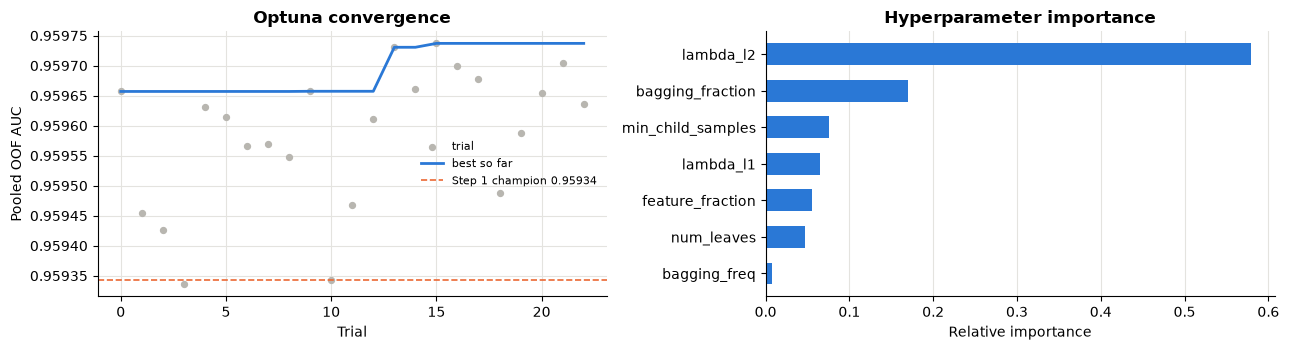

In [5]:
hist = pd.DataFrame([{"trial": t.number, "auc": t.value, **t.params}
                     for t in study.trials if t.value is not None])
hist["best_so_far"] = hist["auc"].cummax()
hist.to_csv(OUT_DIR / "step2_optuna_trials.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].scatter(hist["trial"], hist["auc"], s=18, color=COLOR_MUTED, label="trial")
axes[0].plot(hist["trial"], hist["best_so_far"], color=COLOR_MAIN, linewidth=2, label="best so far")
axes[0].axhline(CHAMP_AUC, color=COLOR_ALT, linestyle="--", linewidth=1.2, label=f"Step 1 champion {CHAMP_AUC:.5f}")
axes[0].set_xlabel("Trial"); axes[0].set_ylabel("Pooled OOF AUC")
axes[0].set_title("Optuna convergence"); axes[0].legend(frameon=False, fontsize=8)

imp = optuna.importance.get_param_importances(study)
axes[1].barh(list(imp.keys())[::-1], list(imp.values())[::-1], color=COLOR_MAIN, height=0.6)
axes[1].set_xlabel("Relative importance"); axes[1].set_title("Hyperparameter importance")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 4. 다중 시드 검증 (Multi-Seed Validation) ★ 낙관 편향 통제

Optuna 최적값은 40회 시행의 **최댓값**이므로 그 자체로 OOF에 대한 선택 편향을 갖는다.
양쪽 모델을 **동일한 seed 3개**로 재학습해 평균을 비교한다 — 한쪽에만 분산 감소 혜택이 가지 않도록.

In [6]:
SEEDS = [42, 2024, 7]
runs = {"champion (num_leaves=63)": CHAMP_PARAMS, "optuna tuned": study.best_params}
multi = {}

for label, params in runs.items():
    res = [evaluate(params, seed=s) for s in SEEDS]
    pooled = np.array([r["pooled"] for r in res])
    folds = np.mean([r["folds"] for r in res], axis=0)
    multi[label] = {"pooled_mean": pooled.mean(), "pooled_std": pooled.std(),
                    "per_seed": pooled, "folds": folds, "res": res}
    print(f"{label:28s} seeds={pooled.round(5).tolist()}  mean={pooled.mean():.5f}  std={pooled.std():.5f}  "
          f"({time.time() - START_TIME:.0f}s)", flush=True)

champion (num_leaves=63)     seeds=[0.95934, 0.95938, 0.95935]  mean=0.95936  std=0.00002  (5108s)


optuna tuned                 seeds=[0.95974, 0.95972, 0.95965]  mean=0.95970  std=0.00004  (5367s)


In [7]:
ch, tu = multi["champion (num_leaves=63)"], multi["optuna tuned"]
d_pool = tu["pooled_mean"] - ch["pooled_mean"]
wins = int((tu["folds"] > ch["folds"]).sum())
adopt = (d_pool > 0) and (wins >= 4)

print(pd.DataFrame({
    "모델": ["champion", "optuna tuned"],
    "3-seed 평균 OOF": [round(ch["pooled_mean"], 5), round(tu["pooled_mean"], 5)],
    "seed 간 std": [round(ch["pooled_std"], 6), round(tu["pooled_std"], 6)],
    "단일 seed(42)": [round(ch["per_seed"][0], 5), round(tu["per_seed"][0], 5)],
}).to_string(index=False))

print(f"\nΔ (3-seed 평균) = {d_pool:+.5f}")
print(f"fold 개선 = {wins}/5   (champion {ch['folds'].round(5).tolist()}")
print(f"                      tuned    {tu['folds'].round(5).tolist()})")
print(f"\n판정: {'✅ 채택' if adopt else '❌ 기각 — Step 1 구성 유지'}")
print(f"참고) Optuna 단일 탐색 최고값 {study.best_value:.5f} vs 3-seed 평균 {tu['pooled_mean']:.5f} "
      f"→ 선택 편향 {study.best_value - tu['pooled_mean']:+.5f}")

          모델  3-seed 평균 OOF  seed 간 std  단일 seed(42)
    champion        0.95936    0.000016      0.95934
optuna tuned        0.95970    0.000036      0.95974

Δ (3-seed 평균) = +0.00034
fold 개선 = 5/5   (champion [0.95944, 0.95834, 0.96023, 0.95932, 0.95951]
                      tuned    [0.95993, 0.95851, 0.9605, 0.95981, 0.95984])

판정: ✅ 채택
참고) Optuna 단일 탐색 최고값 0.95974 vs 3-seed 평균 0.95970 → 선택 편향 +0.00004


## 5. 최종 산출물 저장 (Artifact)

채택 시 `oof_lgbm_tuned.csv` / `test_lgbm_tuned.csv` 로 저장한다.
**시드 평균 앙상블**: 3개 시드의 예측을 평균해 저장하면 단일 시드보다 분산이 낮아 스태킹 입력으로도 유리하다.

In [8]:
if adopt:
    best = tu
    oof_avg = np.mean([r["oof"] for r in best["res"]], axis=0)
    test_avg = np.mean([r["test"] for r in best["res"]], axis=0)
    name = "lgbm_tuned"
    pd.DataFrame({"id": train["id"].values, "fold": fold_id, "pred": oof_avg}).to_csv(OUT_DIR / f"oof_{name}.csv", index=False)
    pd.DataFrame({"id": test["id"].values, "pred": test_avg}).to_csv(OUT_DIR / f"test_{name}.csv", index=False)
    seed_avg_auc = roc_auc_score(y, oof_avg)
    print(f"저장: oof_{name}.csv / test_{name}.csv")
    print(f"3-seed 예측 평균의 OOF AUC = {seed_avg_auc:.5f} (개별 평균 {best['pooled_mean']:.5f} 대비 {seed_avg_auc - best['pooled_mean']:+.5f})")
    pd.Series(study.best_params).to_csv(OUT_DIR / "step2_best_params.csv")
else:
    print("기각 — Step 1 구성(oof_lgbm_fe)을 유지한다. 신규 산출물 없음.")
    # 챔피언의 3-seed 평균이 단일 seed보다 나으면 그것만 갱신 보관
    oof_avg = np.mean([r["oof"] for r in ch["res"]], axis=0)
    test_avg = np.mean([r["test"] for r in ch["res"]], axis=0)
    seed_avg_auc = roc_auc_score(y, oof_avg)
    print(f"참고) 챔피언 3-seed 예측 평균 OOF = {seed_avg_auc:.5f} (단일 seed {CHAMP_AUC:.5f})")
    if seed_avg_auc > CHAMP_AUC:
        pd.DataFrame({"id": train["id"].values, "fold": fold_id, "pred": oof_avg}).to_csv(OUT_DIR / "oof_lgbm_seedavg.csv", index=False)
        pd.DataFrame({"id": test["id"].values, "pred": test_avg}).to_csv(OUT_DIR / "test_lgbm_seedavg.csv", index=False)
        print("  → 시드 평균이 더 우수하므로 oof_lgbm_seedavg.csv 로 별도 저장")

print(f"\n전체 실행 시간: {time.time() - START_TIME:.0f}초")

저장: oof_lgbm_tuned.csv / test_lgbm_tuned.csv
3-seed 예측 평균의 OOF AUC = 0.95986 (개별 평균 0.95970 대비 +0.00016)

전체 실행 시간: 5368초
